In [2]:
import socket
import platform
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("실행 중인 컴퓨터:", socket.gethostname())
print("운영체제:", platform.system(), platform.release())
print("선택한 장치:", device)

if device.type == "cuda":
    print("GPU 이름:", torch.cuda.get_device_name(device))

실행 중인 컴퓨터: junea-Precision-Tower-7910
운영체제: Linux 5.15.0-139-generic
선택한 장치: cuda
GPU 이름: NVIDIA RTX A6000


# TensorFlow와 PyTorch의 차이점

## TensorFlow

- Keras와 통합되어 있어 고수준 API로 모델을 만들고 학습시키기 편리합니다.
- 대규모 데이터 파이프라인, 모델 배포, 엣지 환경 지원에 강점이 있습니다.

## PyTorch

- 동적 계산 그래프를 기반으로 하며, 파이썬 코드처럼 직관적으로 작성하고 디버깅하기 편리합니다.
- 학술 연구와 최신 생성형 AI, LLM 모델 생태계에서 널리 사용됩니다.

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# TensorFlow 대신 PyTorch 사용
import torch
import torch.nn as nn           # PyTorch의 신경망 모듈을 가져옴, 텐서플로우-> fromrensorflow.keras import layers, losses를 대체 

from sklearn.metrics import accuracy_score, precision_score, recall_score   
from sklearn.model_selection import train_test_split

# Fashion MNIST 데이터와 이미지 변환
from torchvision import datasets, transforms        # 데이터셋 불러오기와 이미지 변환, 텐서플로우-> from tensorflow.keras.datasets import fashion_mnist를 대체

# 데이터를 묶어서 전달
from torch.utils.data import DataLoader             # 데이터를 배치 단위로 전달

/home/junea/.local/lib/python3.8/site-packages/sklearn/utils/multiclass.py:13: DeprecationWarning: Please use `spmatrix` from the `scipy.sparse` namespace, the `scipy.sparse.base` namespace is deprecated.
  from scipy.sparse.base import spmatrix


In [4]:
# 이미지를 텐서로 바꾸고, 원본처럼 (28, 28) 형태로 만듦
transform = transforms.Compose([
    transforms.ToTensor(),                           # (1, 28, 28)
    transforms.Lambda(lambda image: image.squeeze(0))  # (28, 28)
])

# 학습용 데이터
train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# 테스트용 데이터
test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# TensorFlow 원본과 같이 전체 데이터의 형태 확인
print(train_dataset.data.shape)
print(test_dataset.data.shape)

torch.Size([60000, 28, 28])
torch.Size([10000, 28, 28])


In [5]:
image, label = train_dataset[0]

print("이미지 형태:", image.shape)
print("옷 종류 레이블:", label)

이미지 형태: torch.Size([28, 28])
옷 종류 레이블: 9


In [6]:
latent_dim = 64


class Autoencoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()

        self.latent_dim = latent_dim

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, latent_dim),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 784),
            nn.Sigmoid(),
            nn.Unflatten(1, (28, 28))  # 원본처럼 (28, 28)로 복원
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded


autoencoder = Autoencoder(latent_dim)

In [7]:
# 원본 이미지와 복원 이미지의 차이를 계산
criterion = nn.MSELoss()

# 손실을 줄이도록 모델의 가중치를 조정
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.001)

In [8]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)   # 학습 이미지를 매번 다른 순서로 섞어서 32개씩 꺼냄
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)    # 이미지를 검증할 때 사용 순서를 섞을 필요 없어서 false로 설정

In [9]:
for epoch in range(10):
    # 학습: train_loader는 shuffle=True로 설정되어 있음
    autoencoder.train()
    train_loss = 0.0

    for images, _ in train_loader:
        optimizer.zero_grad()
        reconstructed = autoencoder(images)
        loss = criterion(reconstructed, images)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    # 검증: 복원 오차만 계산하고 가중치는 수정하지 않음
    autoencoder.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images, _ in test_loader:
            reconstructed = autoencoder(images)
            loss = criterion(reconstructed, images)
            val_loss += loss.item() * images.size(0)

    train_loss /= len(train_loader.dataset)
    val_loss /= len(test_loader.dataset)

    print(f"Epoch {epoch + 1}/10 - loss: {train_loss:.4f} - val_loss: {val_loss:.4f}")

Epoch 1/10 - loss: 0.0280 - val_loss: 0.0166
Epoch 2/10 - loss: 0.0148 - val_loss: 0.0137
Epoch 3/10 - loss: 0.0131 - val_loss: 0.0128
Epoch 4/10 - loss: 0.0124 - val_loss: 0.0122
Epoch 5/10 - loss: 0.0120 - val_loss: 0.0120
Epoch 6/10 - loss: 0.0118 - val_loss: 0.0119
Epoch 7/10 - loss: 0.0117 - val_loss: 0.0118
Epoch 8/10 - loss: 0.0117 - val_loss: 0.0117
Epoch 9/10 - loss: 0.0116 - val_loss: 0.0117
Epoch 10/10 - loss: 0.0116 - val_loss: 0.0117


In [10]:
# 원본의 x_test처럼 전처리된 테스트 이미지 전체를 하나의 텐서로 묶기
x_test = torch.cat([images for images, _ in test_loader], dim=0)

autoencoder.eval()
with torch.no_grad():
    encoded = autoencoder.encoder(x_test)
    decoded = autoencoder.decoder(encoded)

encoded_imgs = encoded.cpu().numpy()        # 테스트 이미지마다 64개 숫자로 표현한 h -> 형태(10000, 64)
decoded_imgs = decoded.cpu().numpy()        # h로 복원한 이미지 -> 형태(10000, 28, 28)

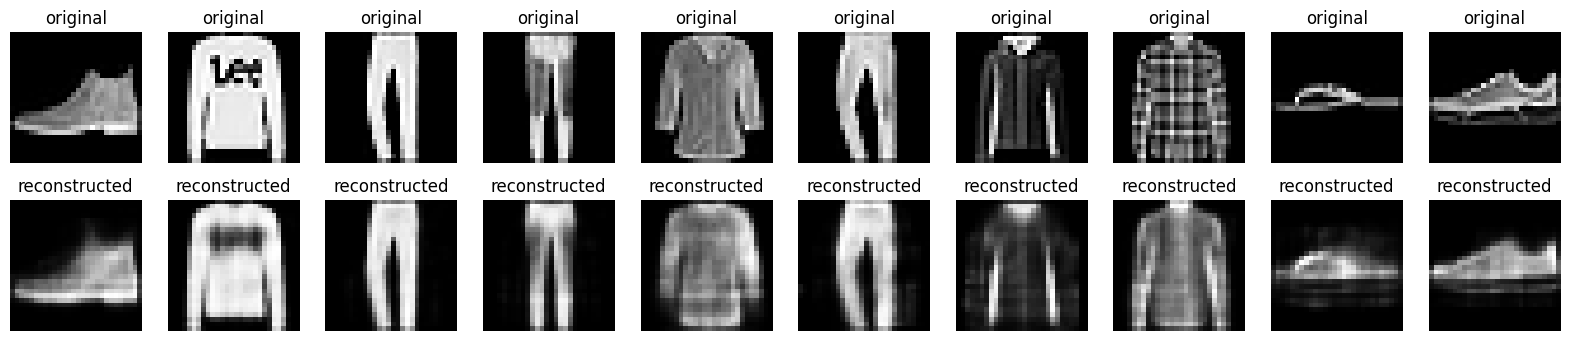

In [11]:
n = 10
fig, axes = plt.subplots(2, n, figsize=(20, 4))

for i in range(n):
    # 윗줄: 원본 이미지
    axes[0, i].imshow(x_test[i].cpu().numpy(), cmap="gray")
    axes[0, i].set_title("original")
    axes[0, i].axis("off")

    # 아랫줄: 같은 이미지를 오토인코더로 복원한 결과
    axes[1, i].imshow(decoded_imgs[i], cmap="gray")
    axes[1, i].set_title("reconstructed")
    axes[1, i].axis("off")

plt.show()

In [12]:
from torchvision import datasets

train_dataset = datasets.FashionMNIST(root="./data", train=True, download=True)
test_dataset = datasets.FashionMNIST(root="./data", train=False, download=True)

x_train = train_dataset.data.float() / 255
x_test = test_dataset.data.float() / 255

x_train = x_train.unsqueeze(1)
x_test = x_test.unsqueeze(1)

print(x_train.shape)

torch.Size([60000, 1, 28, 28])


In [13]:
import torch

noise_factor = 0.2
x_train_noisy = x_train + noise_factor * torch.randn_like(x_train)
x_test_noisy = x_test + noise_factor * torch.randn_like(x_test)

x_train_noisy = torch.clamp(x_train_noisy, min=0., max=1.)
x_test_noisy = torch.clamp(x_test_noisy, min=0., max=1.)

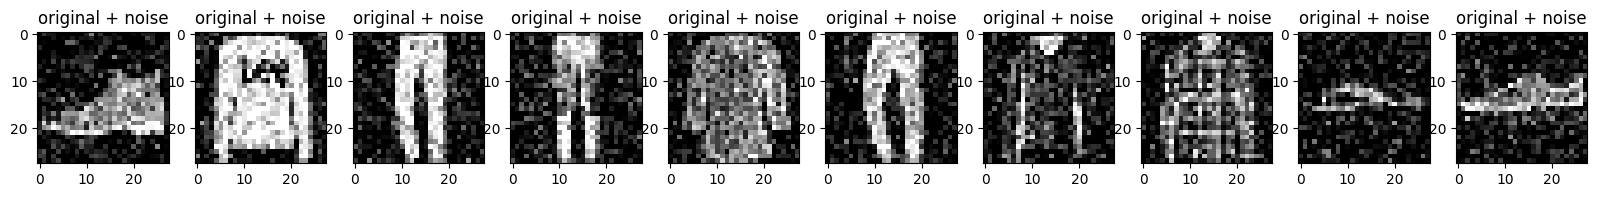

In [14]:
n = 10
plt.figure(figsize=(20, 2))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    plt.title("original + noise")
    plt.imshow(x_test_noisy[i].squeeze(0))
    plt.gray()
plt.show()

In [15]:
import torch.nn as nn

class Denoise(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.ZeroPad2d((0, 1, 0, 1)),  # 오른쪽과 아래쪽에 한 칸 추가
            nn.Conv2d(1, 16, kernel_size=3, stride=2),
            nn.ReLU(),                   # [16, 14, 14]

            nn.ZeroPad2d((0, 1, 0, 1)),
            nn.Conv2d(16, 8, kernel_size=3, stride=2),
            nn.ReLU(),                   # [8, 7, 7]
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(8, 8, kernel_size=3, stride=2),
            nn.ZeroPad2d((0, -1, 0, -1)),  # 오른쪽과 아래쪽 한 칸 제거
            nn.ReLU(),                     # [8, 14, 14]

            nn.ConvTranspose2d(8, 16, kernel_size=3, stride=2),
            nn.ZeroPad2d((0, -1, 0, -1)),
            nn.ReLU(),                     # [16, 28, 28]

            nn.Conv2d(16, 1, kernel_size=3, padding=1),
            nn.Sigmoid(),                  # [1, 28, 28]
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

autoencoder = Denoise().to(device)

In [ ]:
# 복원 이미지와 깨끗한 원본 이미지의 픽셀 차이를 평가
criterion = nn.MSELoss()        #criterion = 같은 위치의 픽셀끼리 차이를 구해 제곱하고 평균을 냄

# 방금 만든 Denoise 모델의 가중치를 업데이트할 옵티마이저
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.001)

In [19]:
from torch.utils.data import DataLoader, TensorDataset

# 같은 번호의 두 이미지를 (노이즈 이미지, 깨끗한 원본) 한 쌍으로 묶음
train_pairs = TensorDataset(x_train_noisy, x_train)
test_pairs = TensorDataset(x_test_noisy, x_test)

train_loader = DataLoader(train_pairs, batch_size=32, shuffle=True)
test_loader = DataLoader(test_pairs, batch_size=32, shuffle=False)

for epoch in range(10):
    autoencoder.train()
    train_loss = 0.0

    for noisy, clean in train_loader:
        noisy = noisy.to(device)
        clean = clean.to(device)

        optimizer.zero_grad()                # 이전 배치의 기울기 초기화
        reconstructed = autoencoder(noisy)   # 노이즈 이미지로부터 복원
        loss = criterion(reconstructed, clean)  # 깨끗한 원본과 MSE 계산
        loss.backward()                      # 기울기 계산
        optimizer.step()                     # 모델 가중치 업데이트

        train_loss += loss.item() * noisy.size(0)

    # 매 에포크가 끝나면 테스트 이미지로 복원 오차를 확인
    autoencoder.eval()
    val_loss = 0.0

    with torch.no_grad():
        for noisy, clean in test_loader:
            noisy = noisy.to(device)
            clean = clean.to(device)

            reconstructed = autoencoder(noisy)
            loss = criterion(reconstructed, clean)
            val_loss += loss.item() * noisy.size(0)

    train_loss /= len(train_pairs)
    val_loss /= len(test_pairs)
    print(f"Epoch {epoch + 1}/10 - loss: {train_loss:.4f} - val_loss: {val_loss:.4f}")

Epoch 1/10 - loss: 0.0066 - val_loss: 0.0066
Epoch 2/10 - loss: 0.0066 - val_loss: 0.0066
Epoch 3/10 - loss: 0.0065 - val_loss: 0.0066
Epoch 4/10 - loss: 0.0065 - val_loss: 0.0065
Epoch 5/10 - loss: 0.0065 - val_loss: 0.0065
Epoch 6/10 - loss: 0.0065 - val_loss: 0.0065
Epoch 7/10 - loss: 0.0065 - val_loss: 0.0065
Epoch 8/10 - loss: 0.0065 - val_loss: 0.0065
Epoch 9/10 - loss: 0.0064 - val_loss: 0.0065
Epoch 10/10 - loss: 0.0064 - val_loss: 0.0065


In [20]:
x = x_test_noisy[:1].to(device)  # 이미지 1장을 배치 형태로 가져옴
print("입력:", list(x.shape))

with torch.no_grad():
    for layer in autoencoder.encoder:
        x = layer(x)
        if isinstance(layer, nn.Conv2d):
            params = sum(p.numel() for p in layer.parameters())
            print(f"Conv2d: {list(x.shape)}, 파라미터 {params:,}개")

입력: [1, 1, 28, 28]
Conv2d: [1, 16, 14, 14], 파라미터 160개
Conv2d: [1, 8, 7, 7], 파라미터 1,160개


In [21]:
decoded = x  # 인코더 출력 h: [1, 8, 7, 7]
print("디코더 입력:", list(decoded.shape))

with torch.no_grad():
    for layer in autoencoder.decoder:
        decoded = layer(decoded)
        params = sum(p.numel() for p in layer.parameters())
        print(f"{layer.__class__.__name__}: {list(decoded.shape)}, 파라미터 {params:,}개")

디코더 입력: [1, 8, 7, 7]
ConvTranspose2d: [1, 8, 15, 15], 파라미터 584개
ZeroPad2d: [1, 8, 14, 14], 파라미터 0개
ReLU: [1, 8, 14, 14], 파라미터 0개
ConvTranspose2d: [1, 16, 29, 29], 파라미터 1,168개
ZeroPad2d: [1, 16, 28, 28], 파라미터 0개
ReLU: [1, 16, 28, 28], 파라미터 0개
Conv2d: [1, 1, 28, 28], 파라미터 145개
Sigmoid: [1, 1, 28, 28], 파라미터 0개
